# Publication figures

Regenerates the article-ready figures from the `analysis/` folder in one place.
GPU-dependent steps (ESM-2 / PepBERT embedding) live in their own notebooks and
cache CSVs / PNGs in `figures/`; this notebook reads those caches and the
processed data, so it needs **no GPU**. Missing caches are skipped with a note.

Three article-ready figures are produced:

1. **AMP performance & robustness** - is low AMP R² from uninformative embeddings or an intrinsically hard/noisy landscape; do the large AMP error bars reflect genuine seed sensitivity or evaluation noise; and why does the SCARSE–baseline gap vary across datasets?
2. **Interpretability of the ESM-2 space** - does the model capture biologically coherent structure (not a black box), and which properties drive the target?
3. **Seed & batch diversity in active learning** - seed diversity (Shannon entropy) for AL success, and batch-diversity metrics between acquisition strategies.


In [5]:
import sys, os, string
try:
    import analysis_common as ac
except ModuleNotFoundError:
    sys.path.insert(0, os.getcwd()); import analysis_common as ac
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr

mpl.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 300,
    'font.size': 9.5, 'axes.titlesize': 10, 'axes.labelsize': 9.5,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5, 'legend.fontsize': 8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 0.9, 'figure.facecolor': 'white',
})
FAM_COLOUR = {'AMP': '#d1495b', 'HemoPI2': '#edae49',
              'Substitution': '#3a86ff', 'Indel': '#2a9d8f'}
REP_LABEL  = {'esm': 'SCARSE\n(ESM2)', 'pepbert': 'PepBERT', 'physchem': 'Physchem',
              'morgan': 'Morgan', 'ngram': 'N-gram'}

def panel_letter(ax, k, dx=-30, dy=8):
    ax.annotate(string.ascii_lowercase[k], xy=(0, 1), xycoords='axes fraction',
                xytext=(dx, dy), textcoords='offset points',
                fontsize=12, fontweight='bold', va='bottom')

# Robust display helpers: use analysis_common's if present, else fall back
# (guards against a stale kernel import of analysis_common).
def pd_(x):
    f = getattr(ac, 'pretty_dataset', None)
    return f(x) if callable(f) else str(x).replace('_', ' ')
def pf_(x):
    f = getattr(ac, 'pretty_family', None)
    return f(x) if callable(f) else str(x)

def amp_family(name):   # friendly ids (analysis data layer)
    if name in set(ac.AMP_DATASETS): return 'AMP'
    if name in set(ac.MINIMIZE_DATASETS): return 'HemoPI2'
    if '_indels' in str(name) or str(name).endswith('indels'): return 'Indel'
    return 'Substitution'

# benchmark summaries store datasets under their CSV basename
BENCH_AMP, BENCH_HEMO = {'EC_all_40','SA_all_40','PA_all_40'}, {'hemopi2_all'}
def bench_family(name):
    if name in BENCH_AMP: return 'AMP'
    if name in BENCH_HEMO: return 'HemoPI2'
    if '_indels' in str(name) or str(name).endswith('indels'): return 'Indel'
    return 'Substitution'

FIG = ac.FIG_DIR
def have(csv): return os.path.exists(os.path.join(FIG, csv))
print('figures dir:', FIG)


figures dir: /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures


## Figure 1 — AMP performance & robustness
**Answers R3 (AMP performance), R3 minor (Fig. 2 error bars), and R1.2.**

Four panels:
- **(a)** Ruggedness of each fitness landscape. *x* = how much pairwise
  **sequence** (Levenshtein) distance varies within the dataset; *y* = the
  Spearman correlation between pairwise sequence distance and pairwise
  **target difference**. A high *y* means *nearby sequences have similar
  targets* (a smooth, learnable landscape); near-zero *y* means they do not
  (rugged). The correlation is only interpretable when *x* is non-trivial:
  substitution/indel sets are near-clonal (all few-point mutants of one
  wild-type), so their *x*≈0 and their *y* is uninformative — which is why we
  show *x* explicitly rather than ranking datasets by *y* alone.
- **(b)** Label resolution: fraction of **unique** target values in each
  dataset. AMP/HemoPI2 assays are censored/binned (~0.35–0.42 unique), which
  mechanically caps the attainable R²; substitution/indel labels are
  effectively continuous (~1.0).
- **(c)** Representation geometry: for a group of datasets where SCARSE beats
  the baselines (**high-gap**) and a group where it only ties them
  (**low-gap**), the Spearman correlation between pairwise **embedding**
  distance and pairwise target difference, per representation. Higher = the
  representation places sequences with similar targets close together, which is
  what makes GPR work. Bars are the mean over the datasets in the group; error
  bars are ±1 SD across those datasets.
- **(d)** Seed sensitivity: across-seed standard deviation of SCARSE's Test R²
  (the Fig. 2 error-bar height) at the **smallest training size (20)**, by
  dataset family; error bars are ±1 SD across the datasets in each family.

Panels (a), (b) use the **whole dataset** (intrinsic properties, no training
split); (c) samples up to 400 sequences per dataset; (d) is at training size 20.


saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/fig1_amp_performance_robustness.png
saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/fig1_amp_performance_robustness.pdf


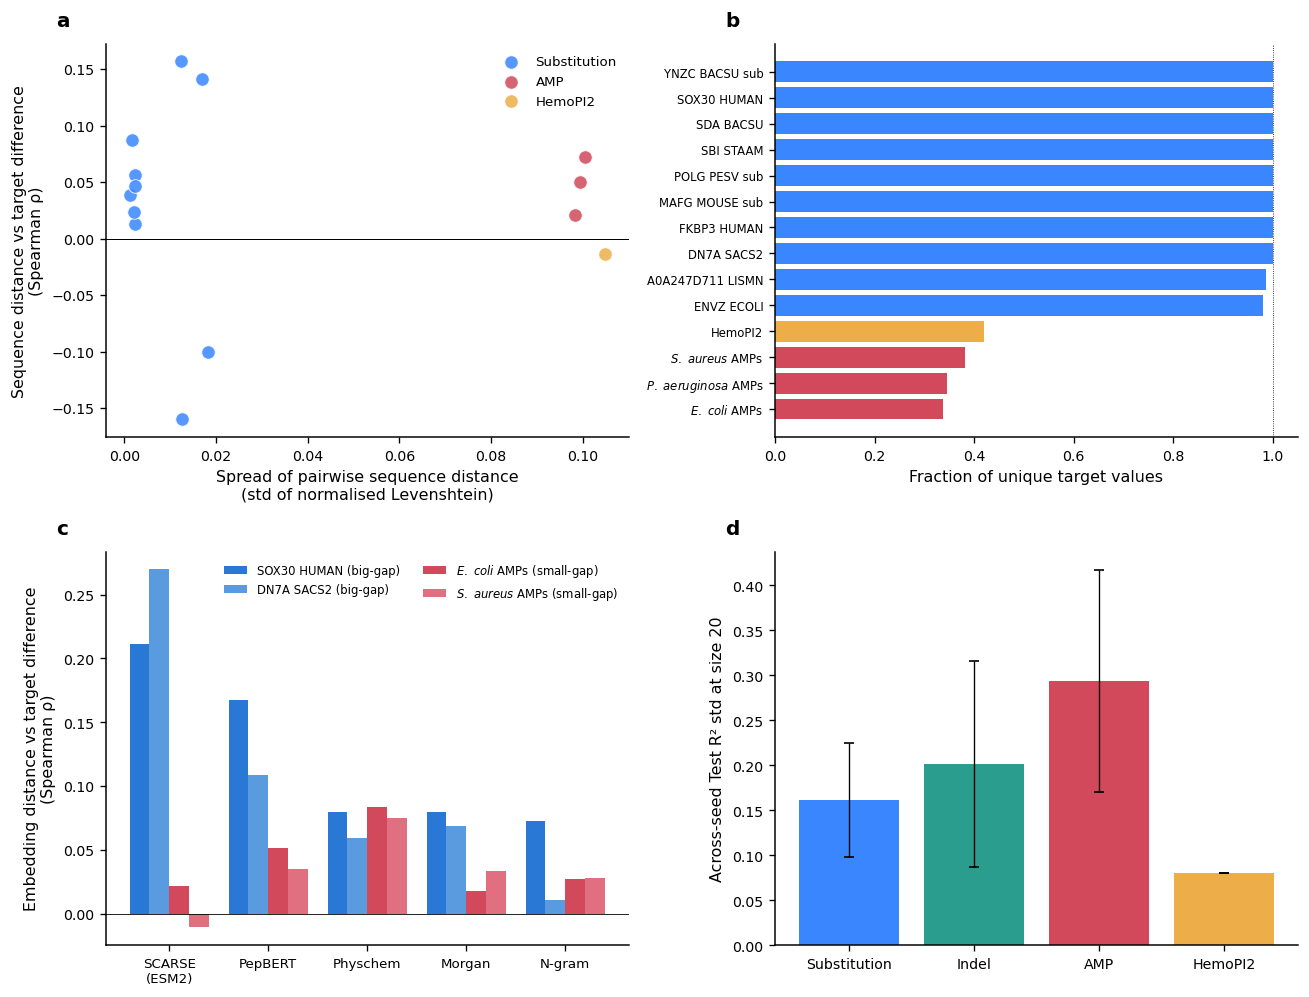

,Dataset,family,rugg_rho,dist_spread,unique_frac
0,Ecoli_AMPs,AMP,0.073,0.100,0.338
1,Saureus_AMPs,AMP,0.021,0.098,0.381
2,Paeruginosa_AMPs,AMP,0.050,0.099,0.346
3,HemoPI2,HemoPI2,-0.014,0.105,0.419
4,A0A247D711_LISMN,Substitution,0.038,0.001,0.986
5,DN7A_SACS2,Substitution,0.013,0.002,1.000
6,ENVZ_ECOLI,Substitution,0.024,0.002,0.980
7,FKBP3_HUMAN,Substitution,0.087,0.002,1.000
8,MAFG_MOUSE_sub,Substitution,0.141,0.017,1.000
9,POLG_PESV_sub,Substitution,-0.160,0.013,1.000


In [12]:
from Levenshtein import distance as _lev
rng = np.random.default_rng(0)

def _rugg_spread(df, n_pairs=4000):
    seqs = df['sequence'].values; y = df['score'].values.astype(float); n = len(seqs)
    if n < 3: return None
    i = rng.integers(0, n, n_pairs); jx = rng.integers(0, n, n_pairs)
    keep = i != jx; i, jx = i[keep], jx[keep]
    sd = np.array([_lev(str(seqs[a]), str(seqs[b])) for a, b in zip(i, jx)], float)
    den = np.array([max(len(str(seqs[a])), len(str(seqs[b]))) for a, b in zip(i, jx)], float)
    sd = np.where(den > 0, sd/den, 0.0); ld = np.abs(y[i] - y[jx])
    rho, _ = spearmanr(sd, ld); return float(rho), float(sd.std())

files = {**ac.PEPTIDE_FILES, **ac.SUBSTITUTION_FILES}
rows = []
for name in files:
    df = ac.load_dataset(name, files=files)
    if df is None: continue
    rs = _rugg_spread(df)
    if rs is None: continue
    u = np.sort(df['score'].unique())
    rows.append({'Dataset': name, 'family': amp_family(name),
                 'rugg_rho': rs[0], 'dist_spread': rs[1], 'unique_frac': len(u)/len(df)})
R = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 2, figsize=(11, 8.4))
axes = axes.ravel()

# (a) ruggedness rho vs edit-distance spread
ax = axes[0]
for fam in [f for f in ['Substitution','Indel','AMP','HemoPI2'] if f in set(R['family'])]:
    g = R[R['family'] == fam]
    ax.scatter(g['dist_spread'], g['rugg_rho'], s=66, alpha=0.85,
               color=FAM_COLOUR.get(fam, '#999'), label=pf_(fam),
               edgecolor='white', linewidth=0.6)
ax.axhline(0, color='k', lw=0.6, zorder=0)
ax.set_xlabel('Spread of pairwise sequence distance\n(std of normalised Levenshtein)')
ax.set_ylabel('Sequence distance vs target difference\n(Spearman ρ)')
ax.legend(frameon=False, fontsize=8, loc='best')
panel_letter(ax, 0)

# (b) label resolution
ax = axes[1]
Rs = R.sort_values('unique_frac')
ax.barh([pd_(d) for d in Rs['Dataset']], Rs['unique_frac'],
        color=[FAM_COLOUR.get(f, '#999') for f in Rs['family']])
ax.axvline(1.0, color='k', lw=0.5, ls=':')
ax.set_xlabel('Fraction of unique target values')
ax.tick_params(axis='y', labelsize=7)
panel_letter(ax, 1)

# (c) embedding geometry: one bar per DATASET within each representation.
# Each (dataset, representation) has a single dist_label_rho, so no averaging.
ax = axes[2]
if have('embedding_geometry.csv'):
    geo = pd.read_csv(os.path.join(FIG, 'embedding_geometry.csv'))
    reps = [r for r in ['esm','pepbert','physchem','morgan','ngram'] if r in set(geo['Representation'])]
    # dataset order: big-gap first, then small-gap, so SCARSE-strong sets group together
    ds_order, ds_group = [], {}
    for grp in ['high-gap', 'low-gap']:
        for d in dict.fromkeys(geo[geo['group'] == grp]['Dataset']):
            if d not in ds_order:
                ds_order.append(d); ds_group[d] = grp
    # blue shades for big-gap datasets, red shades for small-gap, so the two
    # groups stay visually distinct with one bar per dataset
    highs = [d for d in ds_order if ds_group[d] == 'high-gap']
    lows  = [d for d in ds_order if ds_group[d] == 'low-gap']
    blues = ['#2a78d6', '#5a9be0', '#8fbdec', '#b9d6f3']
    reds  = ['#d1495b', '#e07080', '#ea97a3', '#f2bdc5']
    ds_palette = {}
    for i, d in enumerate(highs): ds_palette[d] = blues[i % len(blues)]
    for i, d in enumerate(lows):  ds_palette[d] = reds[i % len(reds)]
    n_ds = len(ds_order); x = np.arange(len(reps)); w = 0.8 / max(n_ds, 1)
    for k, d in enumerate(ds_order):
        vals = (geo[geo['Dataset'] == d].set_index('Representation')['dist_label_rho']
                .reindex(reps).values)
        base = pd_(d)
        lbl = base + (' (big-gap)' if ds_group[d] == 'high-gap' else ' (small-gap)')
        ax.bar(x + k*w - 0.4 + w/2, vals, w, color=ds_palette[d], label=lbl)
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xticks(x); ax.set_xticklabels([REP_LABEL.get(r, r) for r in reps], fontsize=8)
    ax.set_ylabel('Embedding distance vs target difference\n(Spearman ρ)')
    ax.legend(frameon=False, fontsize=7, ncol=2, loc='upper right')
else:
    ax.text(0.5, 0.5, 'Run embedding_geometry.ipynb (GPU)\nto populate panel (c)',
            ha='center', va='center', color='#777'); ax.set_xticks([]); ax.set_yticks([])
panel_letter(ax, 2)

# (d) benchmark seed variance at smallest training size, by family, with SD across datasets
ax = axes[3]
frames = []
for group in ['peptides', 'substitutions', 'indels']:
    s = ac.load_benchmark_summary(group)
    if s is not None:
        s = s.copy(); s['family'] = s['Dataset'].map(bench_family); frames.append(s)
if frames:
    allsum = pd.concat(frames, ignore_index=True)
    scarse = allsum[allsum['Representation'] == 'esm'].copy()
    smallest = scarse['Train Size'].min()
    at_small = scarse[scarse['Train Size'] == smallest]
    fam_order = [f for f in ['Substitution','Indel','AMP','HemoPI2'] if f in set(at_small['family'])]
    means = [at_small[at_small['family']==f]['Test R2 Std'].mean() for f in fam_order]
    sds   = [at_small[at_small['family']==f]['Test R2 Std'].std(ddof=0) for f in fam_order]
    ax.bar(fam_order, means, yerr=sds, capsize=3,
           color=[FAM_COLOUR.get(f, '#999') for f in fam_order], error_kw=dict(lw=0.8))
    ax.set_ylabel(f'Across-seed Test R² std at size {int(smallest)}')
else:
    ax.text(0.5, 0.5, 'Run benchmark + aggregation\nto populate panel (d)',
            ha='center', va='center', color='#777'); ax.set_xticks([]); ax.set_yticks([])
panel_letter(ax, 3)

fig.tight_layout()
ac.savefig(fig, 'fig1_amp_performance_robustness'); plt.show()
R.round(3)


## Figure 2 — Interpretability of the ESM-2 space
**Answers R3.3 (biological coherence / not a black box) and R1.2.**

- **UMAP panels** of the ESM-2 embedding space for the two interpretability
  datasets (rows), coloured by peptide property (columns: target, net charge,
  GRAVY, length). Gradients or clusters mean the space encodes those
  properties. Drawn natively from `interpretability_umap_coords.csv`.
- **Bottom row:** Spearman correlation of simple physicochemical features with
  the oriented target, for *E. coli* AMP and HemoPI2. Charge drives
  antimicrobial potency; hydrophobicity and length drive haemolysis -
  different, biologically coherent drivers per endpoint.


saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/fig2_interpretability.png
saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/fig2_interpretability.pdf


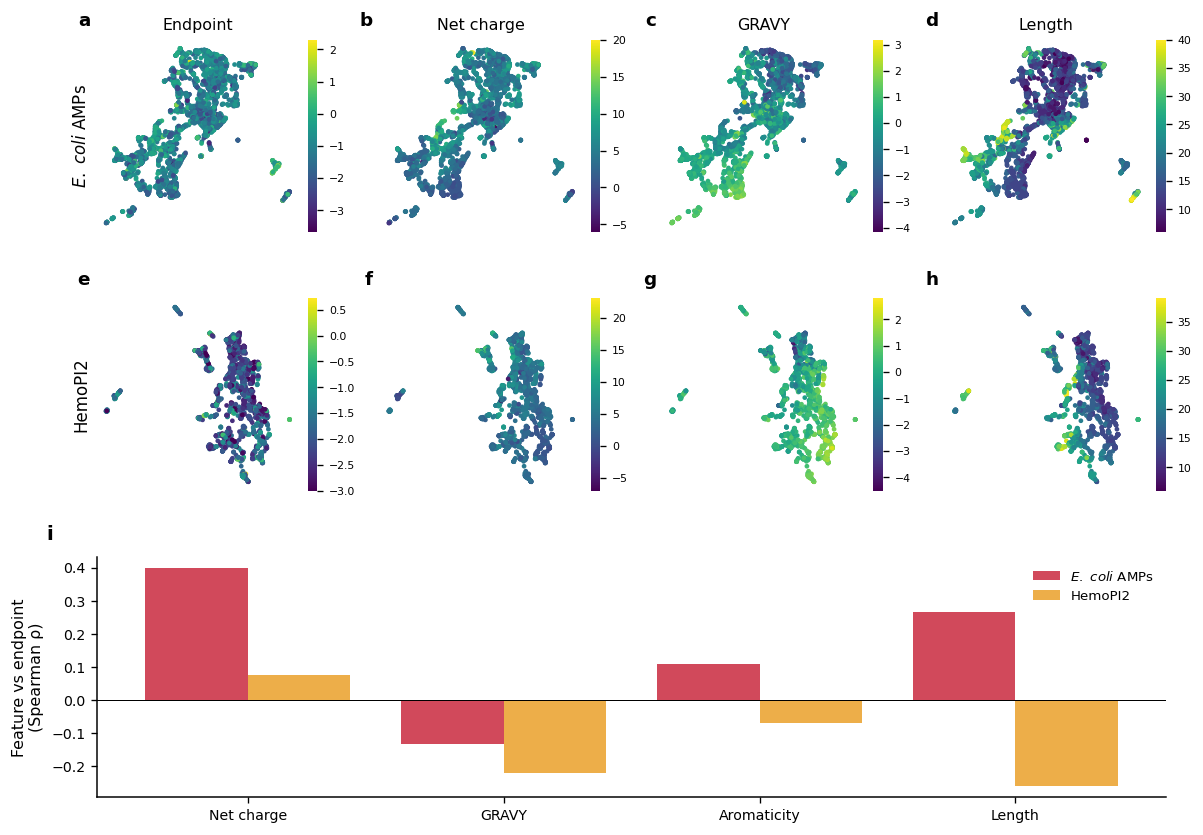

In [11]:
# Figure 2 drawn entirely in matplotlib (no embedded PNG, so no wasted space).
# UMAP coordinates come from interpretability_umap_coords.csv (saved by
# interpretability.ipynb); feature correlations from feature_target_correlation.csv.
COLOUR_BY = [('score', 'Endpoint'), ('net_charge', 'Net charge'),
             ('gravy', 'GRAVY'), ('length', 'Length')]

have_umap = have('interpretability_umap_coords.csv')
have_feat = have('feature_target_correlation.csv')

if have_umap:
    coords = pd.read_csv(os.path.join(FIG, 'interpretability_umap_coords.csv'))
    dsets = list(dict.fromkeys(coords['Dataset']))
    disp = {d: pd_(d) for d in dsets}
    n_umap_rows = len(dsets)
else:
    dsets = []; n_umap_rows = 1

# layout: one row per UMAP dataset (4 property columns) + one row for feature bars
n_rows = n_umap_rows + 1
fig = plt.figure(figsize=(11.5, 2.5*n_umap_rows + 3.2))
gs = fig.add_gridspec(n_rows, 4, height_ratios=[1.0]*n_umap_rows + [1.25],
                      hspace=0.32, wspace=0.28)
letter = 0
if have_umap:
    for r, ds in enumerate(dsets):
        sub = coords[coords['Dataset'] == ds]
        for c, (col, label) in enumerate(COLOUR_BY):
            ax = fig.add_subplot(gs[r, c])
            sc = ax.scatter(sub['x'], sub['y'], c=sub[col], s=8, cmap='viridis',
                            linewidths=0, rasterized=True)
            ax.set_xticks([]); ax.set_yticks([])
            for s in ('top','right','left','bottom'): ax.spines[s].set_visible(False)
            if r == 0: ax.set_title(label, fontsize=9.5)
            if c == 0: ax.set_ylabel(disp[ds], fontsize=10)
            cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
            cb.ax.tick_params(labelsize=6.5); cb.outline.set_visible(False)
            ax.annotate(string.ascii_lowercase[letter], xy=(0, 1), xycoords='axes fraction',
                        xytext=(-4, 6), textcoords='offset points',
                        fontsize=11, fontweight='bold', va='bottom', ha='right')
            letter += 1
else:
    ax = fig.add_subplot(gs[0, :]); ax.axis('off')
    ax.text(0.5, 0.5, 'Run interpretability.ipynb (GPU) to produce\ninterpretability_umap_coords.csv',
            ha='center', va='center', color='#777')

# feature-driver bars span the bottom row
axf = fig.add_subplot(gs[n_rows-1, :])
if have_feat:
    feat = pd.read_csv(os.path.join(FIG, 'feature_target_correlation.csv'))
    feats = ['net_charge', 'gravy', 'aromaticity', 'length']
    fdsets = list(dict.fromkeys(feat['Dataset']))
    x = np.arange(len(feats)); w = 0.8 / max(len(fdsets), 1)
    palette = ['#d1495b', '#edae49', '#3a86ff', '#2a9d8f']
    for i, ds in enumerate(fdsets):
        s = feat[feat['Dataset'] == ds].set_index('feature').reindex(feats)
        axf.bar(x + i*w - 0.4 + w/2, s['spearman_rho'].values, w, color=palette[i % len(palette)],
                label=pd_(ds))
    axf.axhline(0, color='k', lw=0.6)
    axf.set_xticks(x); axf.set_xticklabels(['Net charge', 'GRAVY', 'Aromaticity', 'Length'])
    axf.set_ylabel('Feature vs endpoint\n(Spearman ρ)')
    axf.legend(frameon=False)
else:
    axf.text(0.5, 0.5, 'Run interpretability.ipynb first', ha='center', va='center', color='#777')
    axf.set_xticks([]); axf.set_yticks([])
axf.annotate(string.ascii_lowercase[letter], xy=(0, 1), xycoords='axes fraction',
             xytext=(-30, 8), textcoords='offset points',
             fontsize=12, fontweight='bold', va='bottom')

ac.savefig(fig, 'fig2_interpretability'); plt.show()


## Figure 3 — Seed & batch diversity in active learning
**Answers R2.2 (Shannon entropy recommendation) and R3.2 (batch diversity).**

- **(a)** Does a more diverse starting seed help? *x* = Shannon entropy (bits) of
  the initial 20-peptide seed's amino-acid composition; *y* = the campaign's
  endpoint performance (final **Top-10% acquired (%)**). One point per
  (dataset, seed) for **SCARSE + greedy**; the Pearson *r* across all points is
  in the legend.
- **(b, c)** How diverse is each **newly acquired batch of 20** (not the
  cumulative set), by acquisition strategy, for **SCARSE** across all datasets:
  (b) mean pairwise normalised Levenshtein within the batch, (c) embedding-space
  variance of the batch. Points are the mean over datasets × seeds at each
  training size; error bars are ±1 SD across those runs.


saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/fig3_diversity_activelearning.png
saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/fig3_diversity_activelearning.pdf


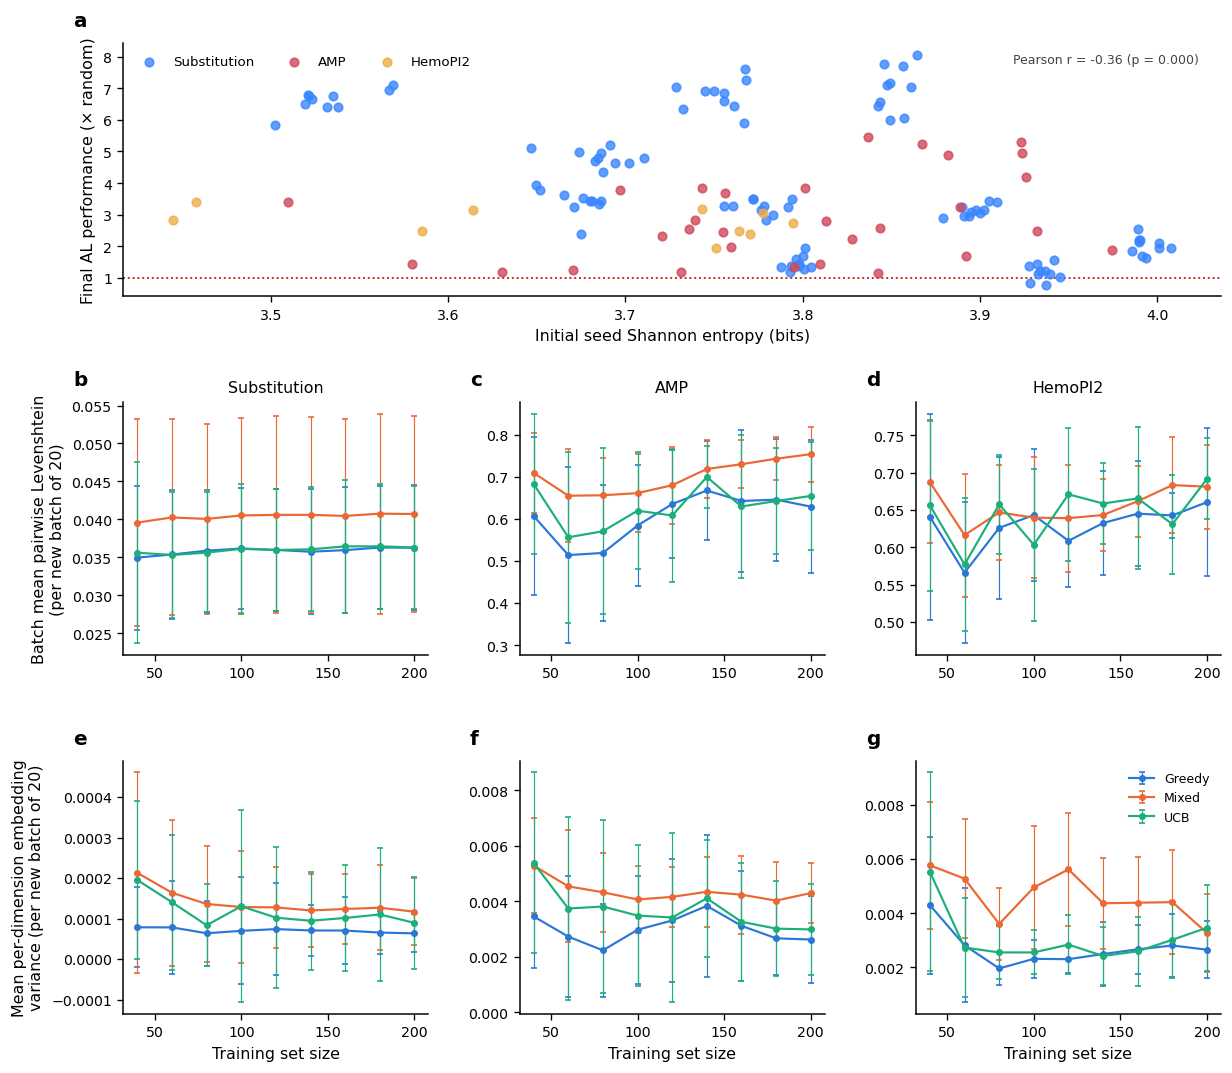

In [9]:
df = ac.load_al_results()
if df is not None:
    df = df.copy(); df['Value'] = pd.to_numeric(df['Value'], errors='coerce')
    df['dstype'] = df['Dataset'].map(amp_family)       # Substitution / AMP / HemoPI2 / Indel
    TYPE_ORDER = [t for t in ['Substitution', 'AMP', 'HemoPI2'] if t in set(df['dstype'])]

    # --- "Final AL performance (x random)" normalisation --------------------
    # Port of selecting_workflow_eval.ipynb: the endpoint Top-10%-acquired (%)
    # is divided by what random selection would reach after screening
    # ENDPOINT_SAMPLES, so 1.0 == no better than random. Random would find
    # ENDPOINT_SAMPLES / pool_size of the top 10%, i.e. pct_random percent.
    # Pool size = number of rows in each dataset's processed CSV, read from disk.
    DATA_ROOT = os.path.join(ac.FIG_DIR, '..', '..', '..', 'data')  # repo-root/data; adjust if needed
    ENDPOINT_SAMPLES = 200
    AL_DATASETS = {  # AL Dataset label -> processed CSV, relative to DATA_ROOT
        'A0A247D711_LISMN': 'proteingym_dms/processed/substitutions/A0A247D711_LISMN_Stadelmann_2021.csv',
        'DN7A_SACS2':       'proteingym_dms/processed/substitutions/DN7A_SACS2_Tsuboyama_2023_1JIC.csv',
        'ENVZ_ECOLI':       'proteingym_dms/processed/substitutions/ENVZ_ECOLI_Ghose_2023.csv',
        'FKBP3_HUMAN':      'proteingym_dms/processed/substitutions/FKBP3_HUMAN_Tsuboyama_2023_2KFV.csv',
        'MAFG_MOUSE_sub':   'proteingym_dms/processed/substitutions/MAFG_MOUSE_Tsuboyama_2023_1K1V.csv',
        'POLG_PESV_sub':    'proteingym_dms/processed/substitutions/POLG_PESV_Tsuboyama_2023_2MXD.csv',
        'SBI_STAAM':        'proteingym_dms/processed/substitutions/SBI_STAAM_Tsuboyama_2023_2JVG.csv',
        'SDA_BACSU':        'proteingym_dms/processed/substitutions/SDA_BACSU_Tsuboyama_2023_1PV0.csv',
        'SOX30_HUMAN':      'proteingym_dms/processed/substitutions/SOX30_HUMAN_Tsuboyama_2023_7JJK.csv',
        'YNZC_BACSU_sub':   'proteingym_dms/processed/substitutions/YNZC_BACSU_Tsuboyama_2023_2JVD.csv',
        'Ecoli_AMPs':       'ecoli_amps/processed/EC_all_40.csv',
        'Saureus_AMPs':     'saureus_amps/processed/SA_all_40.csv',
        'Paeruginosa_AMPs': 'paeruginosa_amps/processed/PA_all_40.csv',
        'HemoPI2':          'hemopi2/processed/hemopi2_all.csv',
    }
    pool_size = {}
    for lbl, rel in AL_DATASETS.items():
        p = os.path.normpath(os.path.join(DATA_ROOT, rel))
        if os.path.exists(p):
            pool_size[lbl] = len(pd.read_csv(p))
        else:
            print(f'[fig3a] missing processed CSV, {lbl} dropped from panel (a): {p}')
    # pct_random[d] = percent of the top 10% that random screening of
    # ENDPOINT_SAMPLES sequences would recover for dataset d.
    pct_random = {d: ENDPOINT_SAMPLES / n * 100 for d, n in pool_size.items()}

    def endpoint(rep='esm', acq='greedy'):
        sub = df[(df['Representation']==rep) & (df['Acquisition']==acq) &
                 (df['Metric']=='Top 10% peptides selected (%)')]
        if sub.empty: return pd.DataFrame()
        idx = sub.groupby(['Dataset','Seed'])['Num_samples'].idxmax()
        ep = sub.loc[idx, ['Dataset','Seed','Num_samples','Value']].copy()
        # express as a multiple of random (x random); needs a known pool size
        ep = ep[ep['Dataset'].isin(pct_random)].copy()
        if (ep['Num_samples'] != ENDPOINT_SAMPLES).any():
            got = sorted(ep.loc[ep['Num_samples'] != ENDPOINT_SAMPLES, 'Num_samples'].unique())
            print(f'[fig3a] note: endpoint step != {ENDPOINT_SAMPLES} for some runs '
                  f'(found {got}); x-random still uses /{ENDPOINT_SAMPLES} as in the eval notebook')
        ep['endpoint'] = ep['Value'] / ep['Dataset'].map(pct_random)
        return ep[['Dataset','Seed','endpoint']]

    ACQ_COLOUR = {'greedy': '#2a78d6', 'mixed': '#eb6834', 'ucb': '#1baf7a'}
    ACQ_LABEL  = {'greedy': 'Greedy', 'mixed': 'Mixed', 'ucb': 'UCB'}
    # Row layout: (a) entropy scatter spanning top; then one row per batch metric,
    # with one column per dataset type.
    ncol = max(len(TYPE_ORDER), 1)
    fig = plt.figure(figsize=(3.6*ncol + 1.0, 10.5))
    gs = fig.add_gridspec(3, ncol, height_ratios=[1.0, 1.0, 1.0], hspace=0.42, wspace=0.30)

    # (a) entropy vs endpoint, spanning the full top row
    axa = fig.add_subplot(gs[0, :])
    ent = (df[df['Metric']=='Initial Seed Shannon Entropy'][['Dataset','Seed','Value']]
           .rename(columns={'Value':'entropy'}).drop_duplicates(['Dataset','Seed']))
    merged = ent.merge(endpoint('esm','greedy'), on=['Dataset','Seed']).dropna()
    if len(merged) >= 3:
        merged['dstype'] = merged['Dataset'].map(amp_family)
        # one legend entry per dataset TYPE (not per dataset), coloured by family
        seen = set()
        for fam in ['Substitution', 'Indel', 'AMP', 'HemoPI2']:
            sub = merged[merged['dstype'] == fam]
            if sub.empty:
                continue
            axa.scatter(sub['entropy'], sub['endpoint'], s=26, alpha=0.8,
                        color=FAM_COLOUR.get(fam, '#999'), label=pf_(fam))
            seen.add(fam)
        r, p = pearsonr(merged['entropy'], merged['endpoint'])
        # Pearson r shown as text in-axes, not as a phantom legend row
        axa.text(0.98, 0.96, f'Pearson r = {r:.2f} (p = {p:.3f})',
                 transform=axa.transAxes, ha='right', va='top', fontsize=7.5, color='#444')
        axa.legend(frameon=False, fontsize=8, ncol=len(seen), loc='upper left')
    else:
        axa.text(0.5, 0.5, 'Not enough AL data yet', ha='center', va='center', color='#777')
    # random-selection reference: 1.0 == no better than random
    axa.axhline(1.0, color='#c0392b', linestyle=(0, (1, 1.4)), linewidth=1.2, zorder=0)
    axa.set_xlabel('Initial seed Shannon entropy (bits)')
    axa.set_ylabel('Final AL performance (× random)')
    panel_letter(axa, 0)

    # (b) and (c): one column per dataset type
    METRICS = [('Batch Mean Levenshtein',
                'Batch mean pairwise Levenshtein\n(per new batch of 20)'),
               ('Batch Embedding Variance',
                'Mean per-dimension embedding\nvariance (per new batch of 20)')]
    k = 1
    for row, (metric, ylab) in enumerate(METRICS, start=1):
        for col, dstype in enumerate(TYPE_ORDER):
            ax = fig.add_subplot(gs[row, col])
            sub = df[(df['Metric']==metric) & (df['Representation']=='esm') & (df['dstype']==dstype)]
            if sub.empty:
                ax.text(0.5, 0.5, 'no data', ha='center', va='center', color='#777')
                ax.set_xticks([]); ax.set_yticks([])
            else:
                agg = sub.groupby(['Acquisition','Num_samples'])['Value'].agg(['mean','std']).reset_index()
                for acq, g in agg.groupby('Acquisition'):
                    g = g.sort_values('Num_samples')
                    ax.errorbar(g['Num_samples'], g['mean'], yerr=g['std'], marker='o', ms=3.2,
                                capsize=2, elinewidth=0.7, lw=1.3,
                                color=ACQ_COLOUR.get(acq, '#555'), label=ACQ_LABEL.get(acq, acq))
                if row == 1:
                    ax.set_title(pf_(dstype), fontsize=9.5)
                if row == len(METRICS):
                    ax.set_xlabel('Training set size')
                if col == 0:
                    ax.set_ylabel(ylab)
                if row == len(METRICS) and col == len(TYPE_ORDER)-1:
                    ax.legend(frameon=False, fontsize=7.5, loc='upper right')
            panel_letter(ax, k); k += 1
    fig.suptitle('')  # ensure no main title
    ac.savefig(fig, 'fig3_diversity_activelearning'); plt.show()
else:
    print('AL df_all.csv not found - run the AL sweep + aggregation first.')